# Fit a microscope from images

**Make images → measure them → fit a new microscope → check its predictions.**

We use **11 lens settings and 99 calibration images**, selected from the earlier 334-image experiment. The fit estimates 19 parameters using hard bounds and **no soft priors**.

This notebook runs on its own. The [reduction study](DATASET_REDUCTION_NOTES.md) explains the choice of settings. The lens model remains our finite, uniform-field solenoid.

In [1]:
from pathlib import Path
import json
import os
import sys

os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")
import jax
jax.config.update("jax_enable_x64", True)

project_folder = next(p for p in [Path.cwd(), *Path.cwd().parents]
                      if (p / "src/temgym_core").is_dir())
example_folder = project_folder / "examples/microscope_models"
results_folder = project_folder / "examples/generated/compact_projector_calibration"
sys.path.insert(0, str(example_folder))

from projector_calibration_workflow import (
    load_measurement_protocol, simulate_calibration_images,
    measure_calibration_images, fit_calibration, check_calibration,
    show_calibration_result,
)
from projector_notebook_helpers import show_images

reuse_completed = True  # False regenerates the images, measurements and fits.

## 1. Supply the measurement settings and starting guess

Each lens setting uses **one ordinary image, four ±3 mrad tilt images and four ±10 nm beam-shift images**. The two pairs of each kind measure the $x$ and $y$ responses.

The protocol contains lens commands and nominal image scales. The separate starting guess supplies lens positions, lengths, strengths and beam parameters. Position and length bounds are engineering assumptions. Their preferred values do not add penalties to this fit.

In [2]:
protocol = load_measurement_protocol(
    path=example_folder / "projector_measurement_protocol.json",
)
starting_guess = json.loads(
    (example_folder / "projector_starting_guess.json").read_text()
)
position_bounds = json.loads(
    (example_folder / "projector_position_priors.json").read_text()
)

print(f"{len(protocol['lens_controls'])} lens settings; 9 images per setting")
starting_guess

11 lens settings; 9 images per setting


{'lens_positions_mm': {'Objective': 2.75,
  'IL1': 196,
  'IL2': 281,
  'IL3': 336,
  'PL1': 399.6},
 'lens_lengths_mm': {'Objective': 0.5,
  'IL1': 6,
  'IL2': 4,
  'IL3': 6,
  'PL1': 1.2},
 'detector_position_mm': 740.2,
 'objective_strength': -0.4,
 'excitation_gains': {'IL1': 0.5, 'IL2': 0.6, 'IL3': 0.5, 'PL1': 0.7},
 'beam_curvature_per_m': 0.0,
 'angular_spread_mrad': 1.2,
 'sample_rotation_deg': 0.0}

## 2. Make the images

**Supply:** recorded lens settings and a noise seed. **Get back:** ordinary, tilt and beam-shift images of the same MAGICAL specimen.

We know the specimen intensity pattern, detector pixel size and 200 kV voltage. The circular illumination radius is 100 nm. Input shifts and tilts are exactly calibrated in this simulation. Only the simulator reads the generating microscope.

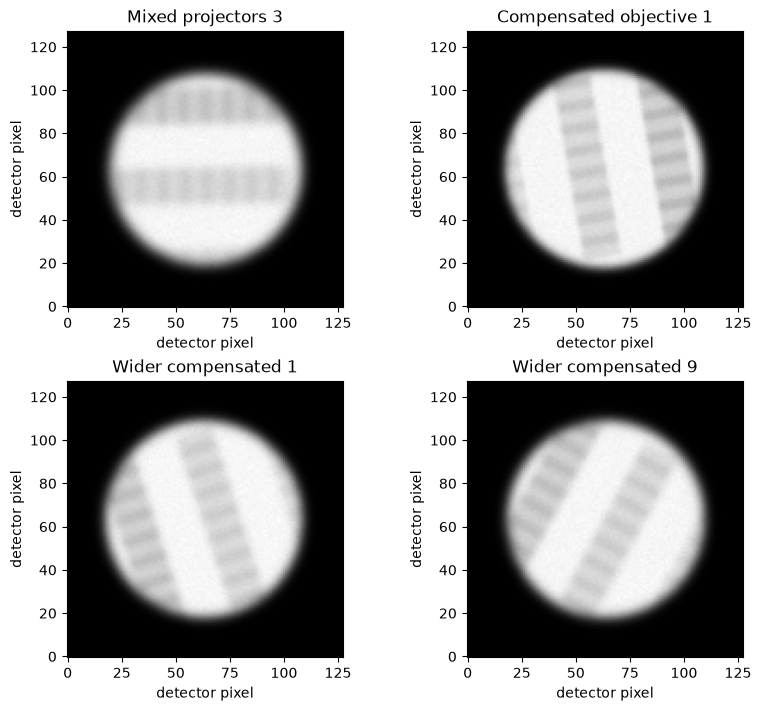

In [3]:
images = simulate_calibration_images(
    protocol=protocol,
    output_directory=results_folder / "calibration",
    random_seed=7301,
    reuse_completed=reuse_completed,
)

show_images(
    images=images.ordinary.images,
    image_labels=images.ordinary.image_labels,
    indices=[0, 4, 6, 10],
)

## 3. Measure the images

**Supply:** images and the known specimen/detector. **Get back:** image scale, rotation, blur and calibrated pair displacements, with their uncertainties.

In our ray coordinates,

$$
\begin{pmatrix}\mathbf r_d\\\boldsymbol\theta_d\\1\end{pmatrix}
=
\begin{pmatrix}A&B&\mathbf t\\C&D&\mathbf u\\0&0&1\end{pmatrix}
\begin{pmatrix}\mathbf r_s\\\boldsymbol\theta_s\\1\end{pmatrix},
\qquad \mathbf r=(x,y)^T,\quad\boldsymbol\theta=(\theta_x,\theta_y)^T.
$$

Here $A$, $B$, $C$ and $D$ are $2\times2$ blocks, so this is a $5\times5$ matrix. Pair displacements measure

$$\Delta\mathbf r_d=A\,\Delta\mathbf s+B\,\Delta\boldsymbol\alpha.$$

The specimen stays fixed while illumination and its wavefront move together. Image analysis separates the texture from the illumination boundary. It receives no lens parameters.

In [4]:
measurements = measure_calibration_images(
    images=images,
    reuse_completed=reuse_completed,
)

## 4. Fit the microscope

**Supply:** measured responses, known specimen/detector settings, starting guess and hard bounds. **Get back:** a fitted microscope, results from 20 starting guesses and a local uncertainty estimate.

One procedure is used for every guess: fit the **16 optical parameters from displacements**, then fit **all 19 parameters** using all measured responses. Both stages have no soft penalties. The three additional parameters describe illumination curvature, angular spread and specimen rotation.

In [5]:
fitted = fit_calibration(
    measurements=measurements,
    specimen_and_detector=images.ordinary.specimen_and_detector,
    starting_guess=starting_guess,
    position_bounds=position_bounds,
    number_of_starts=20,
    output_directory=results_folder / "fit",
    reuse_completed=reuse_completed,
)

## 5. Test predictions at new settings

Make **72 separate images at eight new settings** and measure them in the same way. Compare their responses with the frozen fitted microscope. These images are not used in a refit.

In [6]:
prediction_protocol = load_measurement_protocol(
    path=example_folder / "projector_prediction_protocol.json",
)
new_images = simulate_calibration_images(
    protocol=prediction_protocol,
    output_directory=results_folder / "predictions",
    random_seed=7401,
    reuse_completed=reuse_completed,
)
new_measurements = measure_calibration_images(
    images=new_images,
    reuse_completed=reuse_completed,
)
checks = check_calibration(
    fitted=fitted,
    calibration_images=images,
    validation_measurements=new_measurements,
    starting_guess=starting_guess,
    position_bounds=position_bounds,
)

## 6. Compare with the generating microscope

The parameter error compares the fit with truth, read only now for scoring. The local standard error comes from measurement sensitivity near the fit; it is not a global uniqueness guarantee. Prediction errors are in measurement-noise units.

We also report prediction error after including the fitted parameters’ local uncertainty. This accounts for correlations between predictions and does not refit the model.

In [7]:
show_calibration_result(fitted=fitted, checks=checks)

Check,Result
Images used in fit,99
Starting guesses reaching the same fit,20/20
Largest parameter error,0.425%
Largest local standard error,0.282%
"New images, no refit",72 images; RMS 1.477 noise units
Prediction including local fit uncertainty,RMS 0.996 uncertainty units
Constraints,Hard bounds only; no soft penalties


Parameter,Truth,Fit,Error
lens_positions_mm.Objective,2.3,2.29999,-0.000%
lens_positions_mm.IL1,213.524,213.631,+0.050%
lens_positions_mm.IL2,290.48,290.642,+0.056%
lens_positions_mm.IL3,352.98,353.217,+0.067%
lens_positions_mm.PL1,407.983,408.308,+0.080%
lens_lengths_mm.Objective,0.4,0.399943,-0.014%
lens_lengths_mm.IL1,5,5.00465,+0.093%
lens_lengths_mm.IL2,5,5.00502,+0.100%
lens_lengths_mm.IL3,5,5.00997,+0.199%
lens_lengths_mm.PL1,1,1.00215,+0.215%


The [study notes](DATASET_REDUCTION_NOTES.md) record the smaller datasets, failed starts and independent noise checks. Eleven settings are a tested compromise, not a proven minimum.

Some controls still reach 3–4× reference excitation. Reducing image count does not establish hardware feasibility. This remains a test of the assumed solenoid and specimen-intensity model. The [lens comparison](LENS_MODEL_COMPARISON.md) describes the older TemGym component.